# Every example, emulated

Every example of this repository is emulated on this page, beside what the machines gave when it was sent. To run the page: **Run > Run All Cells**. It needs no account and no token, and nothing is sent to a machine.

Your computer computes what the machine would do. The emulator is in `tools/emulate.py`, in Python's standard library alone: a state vector, with a simple noise model for learning. Beside it stand the results of two other emulators, with no noise: Qrisp's, stored in `qrisp_emulated.json` in each folder, and QuTiP's, which runs the same text gate by gate through its package qutip-qip, stored in `qutip_emulated.json`. So this page needs neither Qrisp nor QuTiP. The tutorial on Hamiltonian simulation is in [`hamiltonian/tutorial.ipynb`](hamiltonian/tutorial.ipynb).

In [1]:
import os, sys
from pathlib import Path

if not os.path.exists("tools/emulate.py"):
    raise SystemExit("Open this page from examples/ of a clone, where its files are.")
sys.path.insert(0, os.path.abspath("tools"))

from emulate import Report
from overview import Overview

overview = Overview.of(Path("."))
print(len(overview.folders), "examples")

30 examples


## All of them, in one table

For each job: the qubits it reads, its two-qubit gates, the key a perfect machine gives most often, with its share, the largest difference in any key between our emulator and Qrisp's (`vs Qrisp`) and between ours and QuTiP (`vs QuTiP`, in powers of ten), and the share of that key when the job ran. The last column is empty for a job not sent yet. Each machine has its own form of text, and all three are emulated here. Both differences use the stored results, so this page needs neither Qrisp nor QuTiP. The largest difference to Qrisp is about 0.000009, in `qrisp/ising`: Qrisp's emulator rounds its shares and scales them to sum to 1. The largest difference to QuTiP is 5.0e-09, in `qrisp/qubo`: the stored file holds 8 places.

In [2]:
print(overview.table())

folder                       job                 site       q   2q key                        perfect vs Qrisp vs QuTiP   read
euroqexa-bell                BELL                euroqexa   2    1 00                           0.500 0.000000  1.1e-16  0.480
euroqexa-ghz                 GHZ                 euroqexa   3    2 000                          0.500 0.000000  1.1e-16 
euroqexa-inverse             INVERSE             euroqexa   3    6 011                          1.000 0.000000  1.3e-15 
euroqexa-one-qubit           X                   euroqexa   1    0 1                            1.000 0.000000  0.0e+00 
euroqexa-three-jobs          X                   euroqexa   1    0 1                            1.000 0.000000  0.0e+00 
euroqexa-three-jobs          BELL                euroqexa   2    1 00                           0.500 0.000000  1.1e-16 
euroqexa-three-jobs          BELL_AGAIN          euroqexa   2    1 00                           0.500 0.000000  1.1e-16 
hamiltonian/live    

## What stays readable

Each point is one job that has run: the share of its best key, divided by the share a perfect machine gives it, against the two-qubit gates in its text. One run each, on one day: it shows how much of each answer survived that day, not how good a machine is. The site's compile can change the gates that run: `ising2` and `QRISP` read better than their texts suggest, very likely because the compile merged gates; this is inferred from the counts.

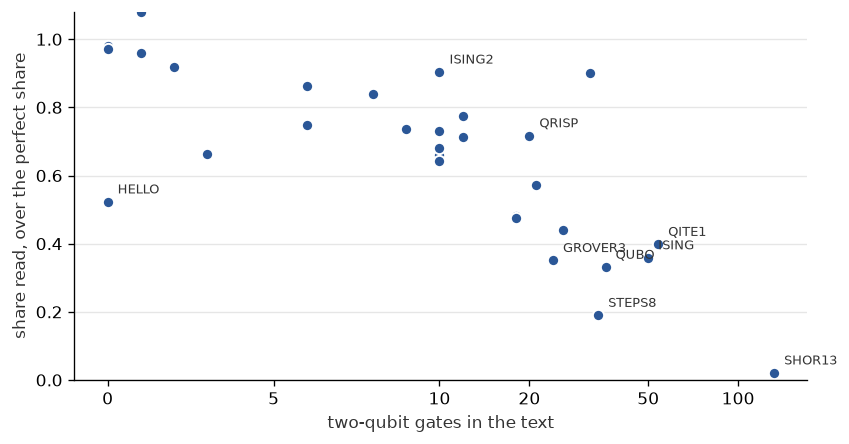

In [3]:
overview.chart();

## Choose one

Put the folder of any example in `NAME`: its circuit, what a perfect machine gives, what Qrisp's emulator and QuTiP gave, and what the machine gave. Its `README.md` says what it does.

Then its first job, gate by gate, up to 20 lines, in QuTiP code from its `emulate_qutip.py` and in Qrisp code from its `emulate_qrisp.py`, to read. Where QuTiP and qutip-qip are installed, or Qrisp, as on Binder, the cell runs each file, which prints what its emulator gives now, with no noise: the same as its stored line above. The QuTiP job of `qrisp/hello` runs on 25 qubits, so the cell does not run it: its `README.md` says what it takes, and in a terminal, `cd examples/qrisp/hello && python emulate_qutip.py` runs it.

Two pictures follow, the same as in its `README.md`: the circuit of one job, drawn by qutip-qip (its first job, or the one its `README.md` names), and the share of each key from each source, as bars.

# Grover's search with one sharp answer

Grover's search looks for one marked value among eight. The usual version finds it with a high chance; Qrisp's exact version (`grovers_alg` with `exact=True`) sets its angles so that a perfect machine finds it in every shot. Here the marked value is 6.


GROVER3: qubits read 3, gates 83, two-qubit gates 24
  a perfect machine  110: 1.000
  Qrisp's emulator, stored, no noise  110: 1.000
  QuTiP, stored, no noise  110: 1.000
  the machine, once  110: 0.351  100: 0.128  011: 0.117  010: 0.110  111: 0.087  001: 0.070  and 2 more

The first job in qrisp/grover3/emulate_qutip.py, a file of 182 lines:

def grover3():
    """The job GROVER3: GROVER3.qasm, on 3 qubits."""
    qc = QubitCircuit(3)
    qc.add_gate("H", targets=[1])
    qc.add_gate("H", targets=[2])
    qc.add_gate("RZ", targets=[1], arg_value=0.531720011788876)
    qc.add_gate("RZ", targets=[2], arg_value=0.531720011788876)
    qc.add_gate("CNOT", controls=[1], targets=[2])
    qc.add_gate

GROVER3: QuTiP, run now, no noise  110: 1.000
Emulated on this computer: nothing was sent.

The first job in qrisp/grover3/emulate_qrisp.py, a file of 174 lines:

def grover3():
    """The job GROVER3: GROVER3.qasm, on 3 qubits."""
    qc = QuantumCircuit(3, 3)
    qc.h(1)
    qc.h(2)
    qc.rz(0.531720011788876, 1)
    qc.rz(0.531720011788876, 2)
    qc.cx(1, 2)
    qc.rz(-0.531720011788876, 2)
    qc.h(0)
    qc.x(0)
    qc.rz(0.531720011788876, 0)
    qc.cx(0, 2)
    qc.rz(0.531720011788876, 2)
    qc.cx(1, 2)
    qc.rz(-0.531720011788876, 2)
    qc.cx(0, 1)
    qc.cx(0, 2)
    qc.rz(-0.531720011788876, 1)
    qc.h(2)
    ...



GROVER3: Qrisp's emulator, run now, no noise  110: 1.000
Emulated on this computer: nothing was sent.


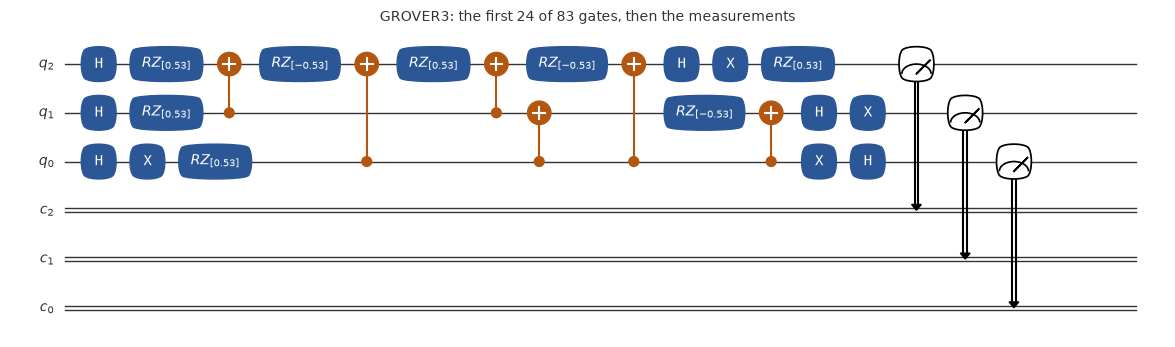

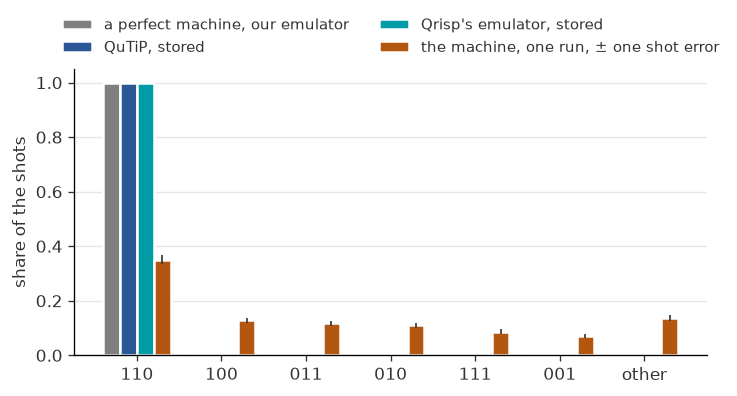

In [4]:
NAME = "qrisp/grover3"

folder = Path(NAME)
print((folder / "README.md").read_text().split("```mermaid")[0])
print(Report(folder / "manifest.json"))
from scripts_shown import show_scripts
show_scripts(folder)

import importlib.util
if importlib.util.find_spec("qutip_qip"):
    from write_pictures import figures
    figures(folder);
else:
    print("qutip-qip is not installed here: see circuit.png and outcomes.png in the folder.")

## Add noise

A real machine makes errors. Here is a simple model: after each two-qubit gate, one of the 15 two-qubit Pauli errors with chance `noise`, and at the end each bit reads wrong with chance `readout`. It is a model for learning, not a model of any machine. Change the numbers, and the example, and watch the answer spread.

The lines of Qrisp's emulator and of QuTiP do not change: they are stored results with no noise, as the emulator Qrisp runs by default has no model of noise and QuTiP runs here with none.

In [5]:
NAME, noise, readout = "qrisp/grover3", 0.03, 0.03

print(Report(Path(NAME) / "manifest.json", shots=1000, noise=noise, readout=readout))

GROVER3: qubits read 3, gates 83, two-qubit gates 24
  a perfect machine  110: 1.000
  Qrisp's emulator, stored, no noise  110: 1.000
  QuTiP, stored, no noise  110: 1.000
  emulated, with noise (1000 shots, seed 1)  110: 0.534  100: 0.091  010: 0.074  111: 0.072  101: 0.066  011: 0.064  and 2 more
  the machine, once  110: 0.351  100: 0.128  011: 0.117  010: 0.110  111: 0.087  001: 0.070  and 2 more


On your own computer, the same from any folder: `./emulate.sh --noise 0.03 --readout 0.03`.

To send an example to a machine you need an account of your own, as a token is personal: the [ENCCS lesson](https://enccs.github.io/eurohpc-quantum-devices-access-hpcqc/) says how to get one, and each folder's README says how to send it.